# EvidenceLab #12 | HOTSPOT ≠ DRIVER
## **Map it. Test the cluster. Localize associations. Form stronger questions.**

**Dr. Amobi Andrew Onovo, PhD, MPH | EvidenceLab**  
**See it. Understand it. Run it.**

---

# 🚀 BEGINNER-FRIENDLY, END TO END

## **NO UPLOADS. NO ACCOUNT KEYS. NO EXTERNAL DATA FILES.**

### **ALL YOU NEED TO DO:**
# **Select `Runtime → Run all` in Google Colab.**

**That is it.** The notebook installs the required Python packages, loads the geographic boundaries automatically, generates all teaching data within the notebook, runs the analyses, and creates the visualizations.

### **You do NOT need to:**
- **upload a dataset**
- **download a separate data file**
- **enter an API or account key**
- **prepare or clean a file before starting**
- **change the code to complete the guided lesson**

> **All teaching data are generated within this notebook. Just click `Runtime → Run all` to execute the complete EvidenceLab #12 workflow from beginning to end.**

---

### Study question
Across a **fully synthetic Sub-Saharan Africa wellbeing study**, where does the outcome **life evaluation** form statistically unusual local clusters, and how do selected contextual associations with life evaluation vary across geography?

### Why this lesson matters
A choropleth can show where values are high or low, but a visually dense area is **not automatically a hotspot**. Getis-Ord Gi* formally tests local clustering. GWR then asks a different question: whether selected predictor–outcome associations vary by place.

> **Hotspot ≠ cause. GWR association ≠ causal effect.**

This notebook is designed for teaching. All outcome and predictor values are synthetic and must not be interpreted as country rankings.


Production copy of v4. Both local Getis–Ord calls set star=True to include the focal unit. The two-sided status of the test depends on the installed PySAL version and test settings. The supplied notebook remains the source. Natural Earth provides public geometry, and the analytical variables are generated in the notebook.

## Roadmap
**PART A** → Set up the spatial laboratory and understand every variable  
**PART B** → Explore the synthetic data with univariate and bivariate EDA  
**PART C** → MAP IT with a descriptive choropleth  
**PART D** → TEST THE CLUSTER with Getis-Ord Gi*  
**PART E** → LOCALIZE ASSOCIATIONS with GWR  
**PART F** → Integrate the evidence and form stronger epidemiologic questions  
**PART G** → Sensitivity analysis, teaching recap, and adaptation to your own data

> **Teaching design:** lightweight interactive EDA is retained where hovering adds learning value. Spatial-result maps use stable, high-resolution static figures so they remain easy to scroll, teach from, export, and reproduce in Colab.


## 0. RUN: Set up your laboratory

### **Beginner instruction: select `Runtime → Run all`. You do not need to run each cell manually.**

**What this section does automatically:** installs and imports the packages used for spatial data, interactive visualization, Getis-Ord Gi*, and GWR.

### **For beginners**
1. Open this notebook in Google Colab.
2. Select **`Runtime → Run all`**.
3. **No data upload is required.**
4. **No account key or API key is required.**
5. **No external teaching dataset needs to be downloaded or attached.**
6. All synthetic teaching data are generated inside this notebook.
7. The geographic boundary layer is retrieved automatically by the notebook.
8. Once execution finishes, scroll through the outputs, hover over interactive charts and maps, and read each interpretation checkpoint.

> **Your only required action for the guided lesson is: `Runtime → Run all`.**


In [1]:
!pip -q install geopandas libpysal esda mgwr mapclassify pyogrio plotly scikit-learn

import warnings, numpy as np, pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from libpysal.weights import Queen, KNN
from esda.getisord import G_Local
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
np.random.seed(42)
print("✓ Spatial laboratory ready.")

✓ Spatial laboratory ready.


# PART A | Build a transparent synthetic spatial study

## 1. Load country boundaries automatically
**What we are trying to achieve:** obtain the geographic polygons needed to join data to place and run spatial analysis.

The code downloads Natural Earth country boundaries and retains Sub-Saharan African countries for this teaching exercise. The geographic boundaries are real map geometry; the analytical values generated later are synthetic.

In [2]:
url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url)

exclude = ["Algeria","Egypt","Libya","Morocco","Tunisia","Western Sahara"]
ssa = (world[(world["CONTINENT"]=="Africa") & (~world["ADMIN"].isin(exclude))]
       .copy().reset_index(drop=True).to_crs(6933))

print(f"✓ Loaded {len(ssa)} country polygons for the synthetic Sub-Saharan Africa study.")
print("Outcome and predictor values have NOT yet been created.")

✓ Loaded 45 country polygons for the synthetic Sub-Saharan Africa study.
Outcome and predictor values have NOT yet been created.


## 2. Define the study variables before generating data
**Why this comes first:** good analysis begins by defining what each variable represents and which variable is the outcome.

### Outcome of interest
**`life_evaluation`** is the synthetic continuous outcome. Higher values represent higher simulated average life evaluation.

### Predictor variables
The predictors represent broad contextual domains commonly used in wellbeing research. They are generated solely for teaching.

The table below is the notebook's **data dictionary**. Use this habit with your own datasets before modelling.

In [3]:
variable_dictionary = pd.DataFrame([
["ADMIN","Identifier","Country/area name used to join results to geography","Text","Geographic identifier"],
["life_evaluation","OUTCOME","Synthetic average life-evaluation score","2.5–7.5","Higher = higher simulated wellbeing"],
["social_support","Predictor","Synthetic proportion-like social-support measure","0.35–0.95","Higher = stronger simulated support"],
["log_gdp_pc","Predictor","Synthetic log GDP-per-capita proxy","Continuous","Higher = greater simulated economic resources"],
["healthy_life_expectancy","Predictor","Synthetic healthy-life-expectancy proxy","Years","Higher = longer simulated healthy lifespan"],
["freedom","Predictor","Synthetic freedom-to-make-life-choices measure","0.35–0.92","Higher = greater simulated freedom"],
["generosity","Predictor","Synthetic generosity index","Continuous, centered near 0","Positive/negative values are allowed"],
["perceived_corruption","Predictor","Synthetic perceived-corruption measure","0.35–0.95","Higher = greater simulated perceived corruption"],
], columns=["Variable","Role","Meaning","Scale / unit","Interpretation"])
display(variable_dictionary)

                  Variable  ...                                   Interpretation
0                    ADMIN  ...                            Geographic identifier
1          life_evaluation  ...              Higher = higher simulated wellbeing
2           social_support  ...              Higher = stronger simulated support
3               log_gdp_pc  ...    Higher = greater simulated economic resources
4  healthy_life_expectancy  ...       Higher = longer simulated healthy lifespan
5                  freedom  ...               Higher = greater simulated freedom
6               generosity  ...             Positive/negative values are allowed
7     perceived_corruption  ...  Higher = greater simulated perceived corruption

[8 rows x 5 columns]


## 3. Generate the synthetic dataset
**What we are trying to achieve:** create a reproducible dataset with deliberately engineered spatial structure so both hotspot analysis and GWR have meaningful patterns to detect.

The data-generating process makes some relationships vary gradually across longitude/latitude. This is deliberate and transparent. It lets beginners see what the methods are designed to recover.

**Important:** these are teaching simulations, not observed country values and not country rankings.

In [4]:
cent = ssa.geometry.centroid
x = (cent.x-cent.x.mean())/cent.x.std()
y = (cent.y-cent.y.mean())/cent.y.std()
n = len(ssa)
rng = np.random.default_rng(12)

ssa["social_support"] = np.clip(.68 + .07*(-y) + rng.normal(0,.06,n), .35,.95)
ssa["log_gdp_pc"] = 8.15 + .30*x + .15*y + rng.normal(0,.28,n)
ssa["healthy_life_expectancy"] = 55 + 2*x + rng.normal(0,2.3,n)
ssa["freedom"] = np.clip(.65 + .05*y + rng.normal(0,.07,n), .35,.92)
ssa["generosity"] = rng.normal(0,.12,n)
ssa["perceived_corruption"] = np.clip(.73 - .05*x + rng.normal(0,.07,n), .35,.95)

east = 1/(1+np.exp(-1.2*x))
south = 1/(1+np.exp(1.0*y))

ssa["life_evaluation"] = (
    4.0
    + (0.28 + 0.30*east)*(ssa["log_gdp_pc"]-8)
    + (1.15 + 0.75*south)*(ssa["social_support"]-.65)
    + .035*(ssa["healthy_life_expectancy"]-55)
    + .55*(ssa["freedom"]-.65)
    - .40*(ssa["perceived_corruption"]-.70)
    + rng.normal(0,.22,n)
)
ssa["life_evaluation"] = np.clip(ssa["life_evaluation"],2.5,7.5)

analysis_cols = ["ADMIN","life_evaluation","social_support","log_gdp_pc",
                 "healthy_life_expectancy","freedom","generosity","perceived_corruption"]

print("✓ Synthetic analytical dataset created.")
print(f"Rows: {len(ssa):,} | Analytical columns shown below: {len(analysis_cols)}")
display(ssa[analysis_cols].head(15).round(3))

✓ Synthetic analytical dataset created.
Rows: 45 | Analytical columns shown below: 8
                               ADMIN  ...  perceived_corruption
0        United Republic of Tanzania  ...                 0.664
1   Democratic Republic of the Congo  ...                 0.674
2                            Somalia  ...                 0.767
3                              Kenya  ...                 0.698
4                              Sudan  ...                 0.657
5                               Chad  ...                 0.862
6                       South Africa  ...                 0.617
7                            Lesotho  ...                 0.762
8                           Zimbabwe  ...                 0.769
9                           Botswana  ...                 0.754
10                           Namibia  ...                 0.713
11                           Senegal  ...                 0.806
12                              Mali  ...                 0.762
13                 

### Interpretation checkpoint: know your data before mapping
The first 15 rows let you see the actual structure you will analyze. `life_evaluation` is the **outcome**. The remaining numeric variables are candidate contextual predictors.

**Key takeaway:** the analysis is not asking which country is "best." It asks whether the synthetic outcome has a spatial pattern and whether selected associations with that outcome vary geographically.

# PART B | Exploratory Data Analysis before spatial modelling

## 4. Why EDA comes before Gi* and GWR
**What we are trying to achieve:** understand the shape, spread, unusual values, and basic predictor–outcome relationships before introducing spatial statistics.

A strong spatial workflow should not begin with a map. First ask:
- What does the outcome distribution look like?
- Which predictors have narrow or wide ranges?
- Are there unusual observations worth checking?
- Which predictors appear positively or negatively related to the outcome?
- Are predictors strongly correlated with one another?

These are **exploratory patterns**, not causal findings.

## 5. Univariate EDA: histogram of the outcome
**Outcome:** `life_evaluation`

A histogram is more useful than a box plot here because beginners can directly see the shape of the synthetic outcome distribution, including concentration, spread, and possible skewness.

The vertical line marks the mean and the dashed line marks the median.

       life_evaluation
count           45.000
mean             4.157
std              0.344
min              3.366
25%              3.959
50%              4.175
75%              4.376
max              4.930


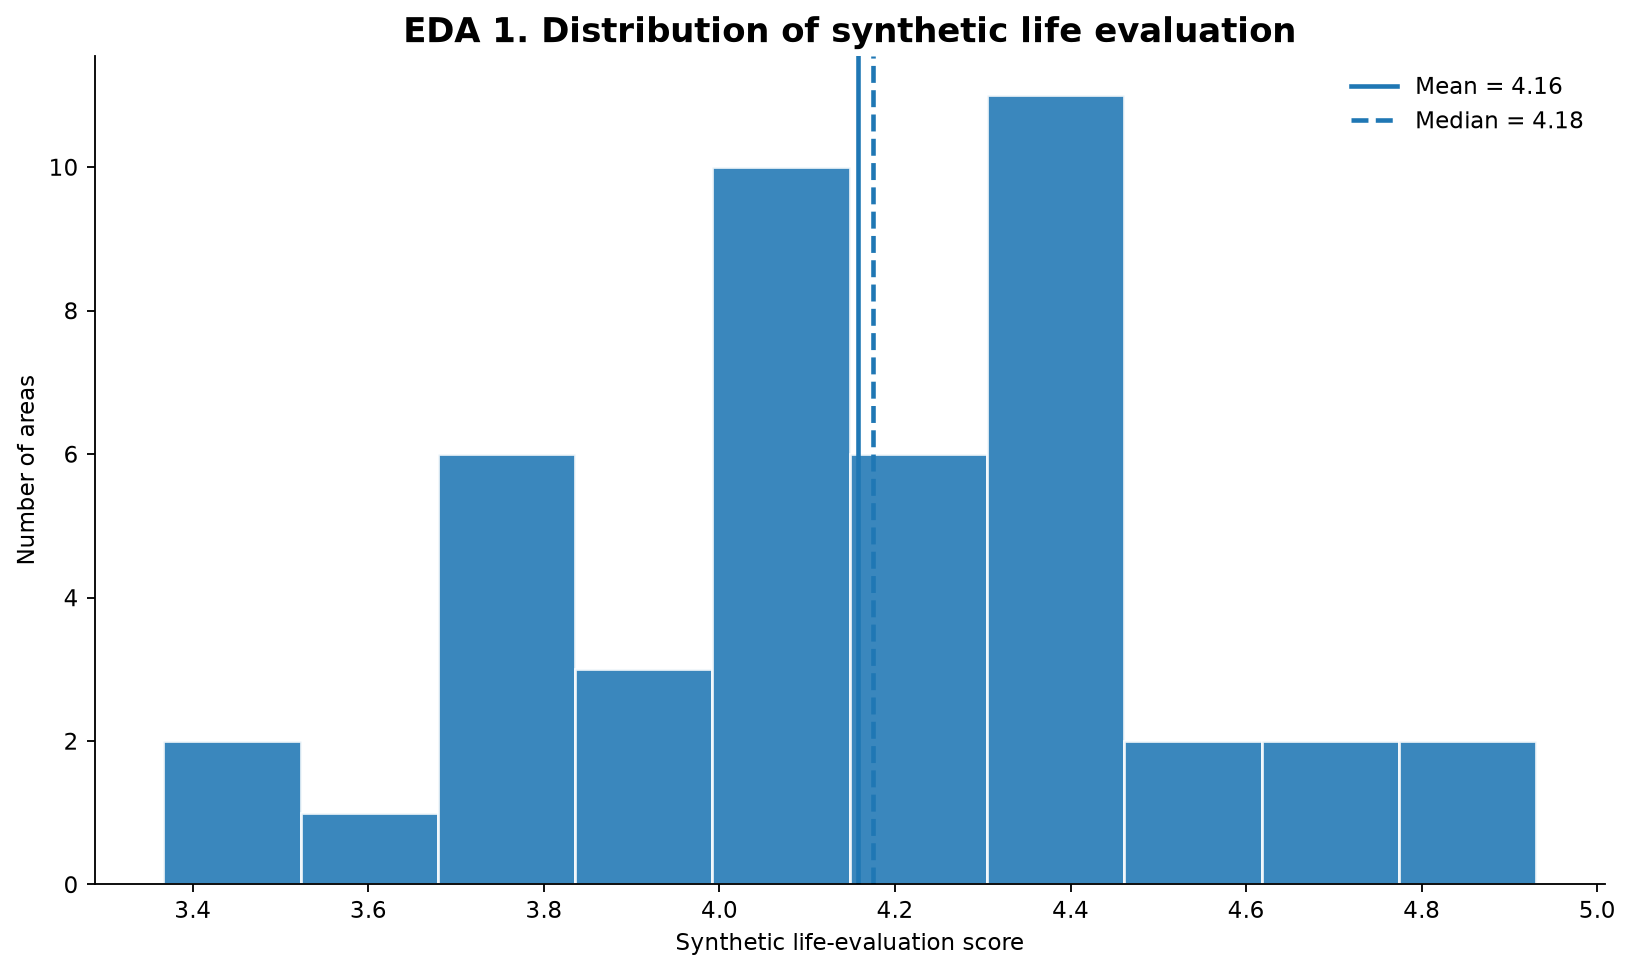

In [5]:
outcome = ssa["life_evaluation"]
fig, ax = plt.subplots(figsize=(10,6))
ax.hist(outcome, bins=10, edgecolor="white", linewidth=1.2, alpha=.88)
ax.axvline(outcome.mean(), linewidth=2, label=f"Mean = {outcome.mean():.2f}")
ax.axvline(outcome.median(), linewidth=2, linestyle="--", label=f"Median = {outcome.median():.2f}")
ax.set_title("EDA 1. Distribution of synthetic life evaluation", fontsize=15, weight="bold")
ax.set_xlabel("Synthetic life-evaluation score")
ax.set_ylabel("Number of areas")
ax.legend(frameon=False)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(outcome.describe().to_frame("life_evaluation").round(3))

### Interpretation
The histogram answers a basic question before any spatial analysis: **what range of outcome values are we trying to explain geographically?**

Compare the mean and median and inspect the overall shape. A large separation could indicate skewness. Very isolated values could deserve additional data-quality review in a real study.

**Key takeaway:** Gi* will later test whether these outcome values are geographically clustered. It does not replace this first step of understanding the outcome itself.

## 6. Univariate EDA: predictor distributions
**What we are trying to achieve:** inspect every candidate predictor before modelling.

These small-multiple histograms make it easier to compare ranges and shapes without mixing variables that have different units.

                         count    mean    std     min  median     max
social_support            45.0   0.682  0.079   0.483   0.688   0.856
log_gdp_pc                45.0   8.169  0.354   7.241   8.217   8.864
healthy_life_expectancy   45.0  54.989  3.108  48.272  54.945  64.099
freedom                   45.0   0.643  0.089   0.419   0.667   0.819
generosity                45.0   0.006  0.104  -0.269  -0.001   0.221
perceived_corruption      45.0   0.739  0.082   0.538   0.754   0.914
life_evaluation           45.0   4.157  0.344   3.366   4.175   4.930


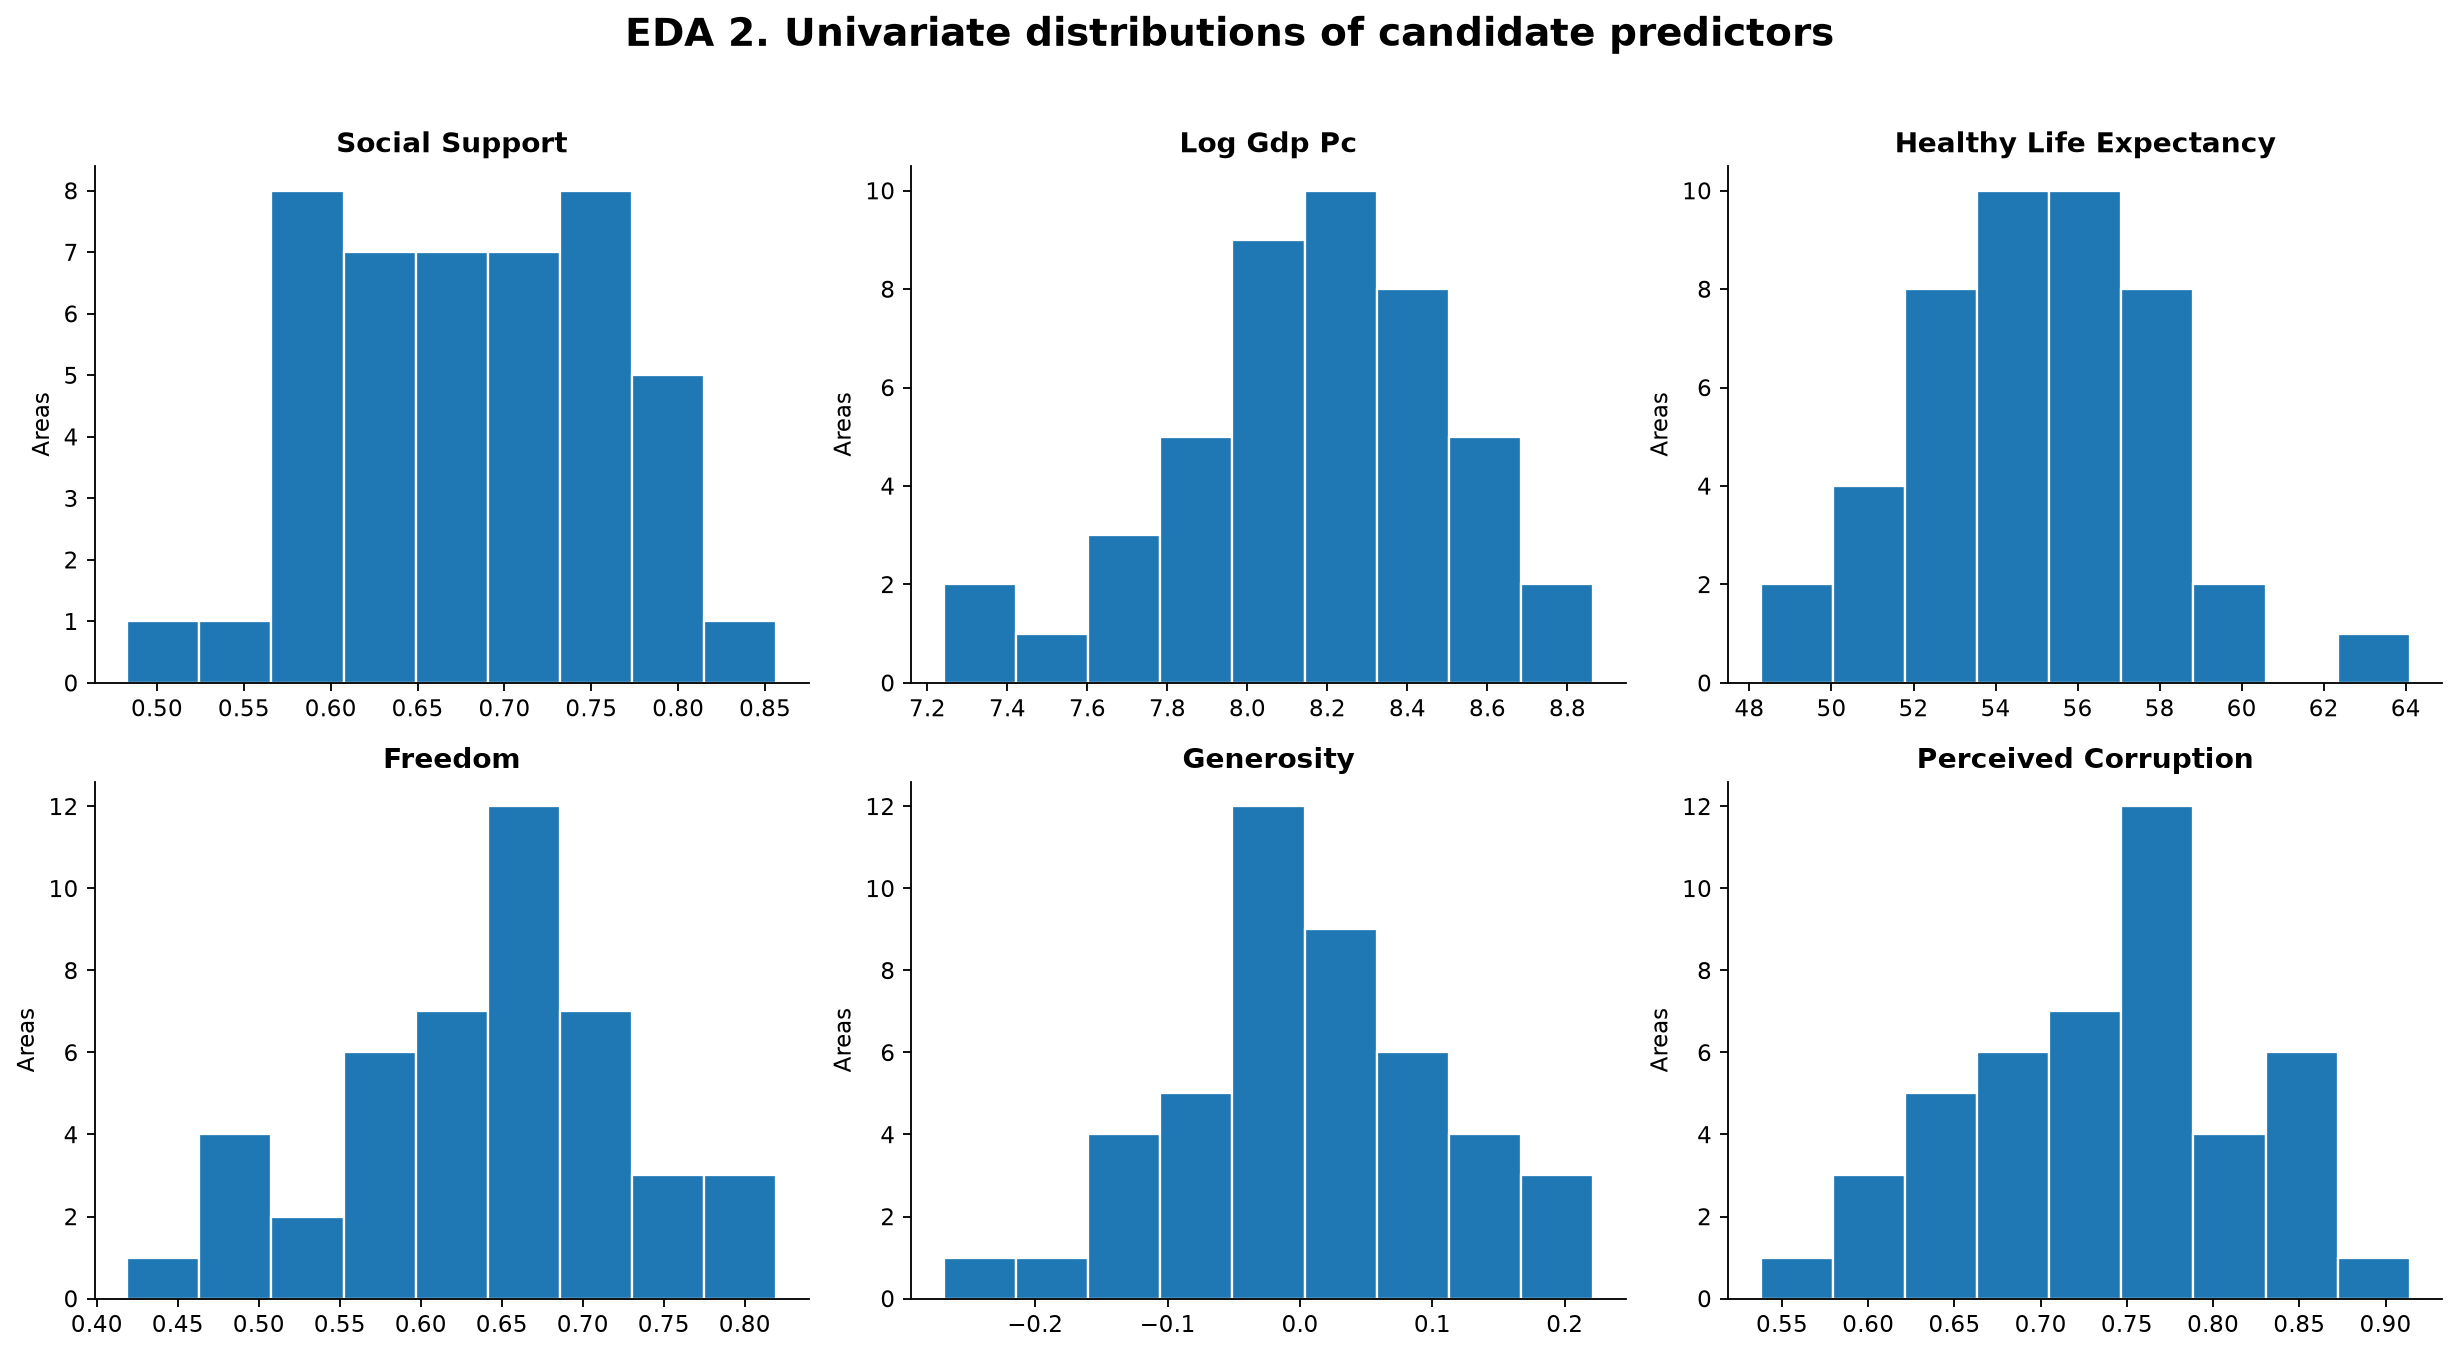

In [6]:
predictors = ["social_support","log_gdp_pc","healthy_life_expectancy",
              "freedom","generosity","perceived_corruption"]

fig, axes = plt.subplots(2,3,figsize=(15,8))
for ax,var in zip(axes.ravel(),predictors):
    ax.hist(ssa[var], bins=9, edgecolor="white", linewidth=1)
    ax.set_title(var.replace("_"," ").title(), weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Areas")
    ax.spines[["top","right"]].set_visible(False)
fig.suptitle("EDA 2. Univariate distributions of candidate predictors", fontsize=17, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

summary = ssa[predictors+["life_evaluation"]].agg(["count","mean","std","min","median","max"]).T
display(summary.round(3))

### Interpretation
Look for variables with very little variation, extreme skewness, or isolated observations. A predictor with almost no variation would contribute little information to a regression model. Extreme values may exert disproportionate influence.

Because these data are synthetic, the distributions reflect the teaching design. With real data, this step is where you would investigate data quality, measurement differences, coding errors, and scientifically implausible values.

## 7. Bivariate EDA: outcome versus each predictor
**What we are trying to achieve:** examine whether each predictor has an apparent positive, negative, weak, or nonlinear relationship with `life_evaluation`.

Each panel shows country-level synthetic observations and a simple linear trend. The line is a descriptive guide only. It is **not** the GWR model and does not account for geography.

                 Predictor  Pearson r with life_evaluation
1               log_gdp_pc                           0.680
2  healthy_life_expectancy                           0.507
0           social_support                           0.366
5     perceived_corruption                          -0.326
4               generosity                           0.282
3                  freedom                          -0.084


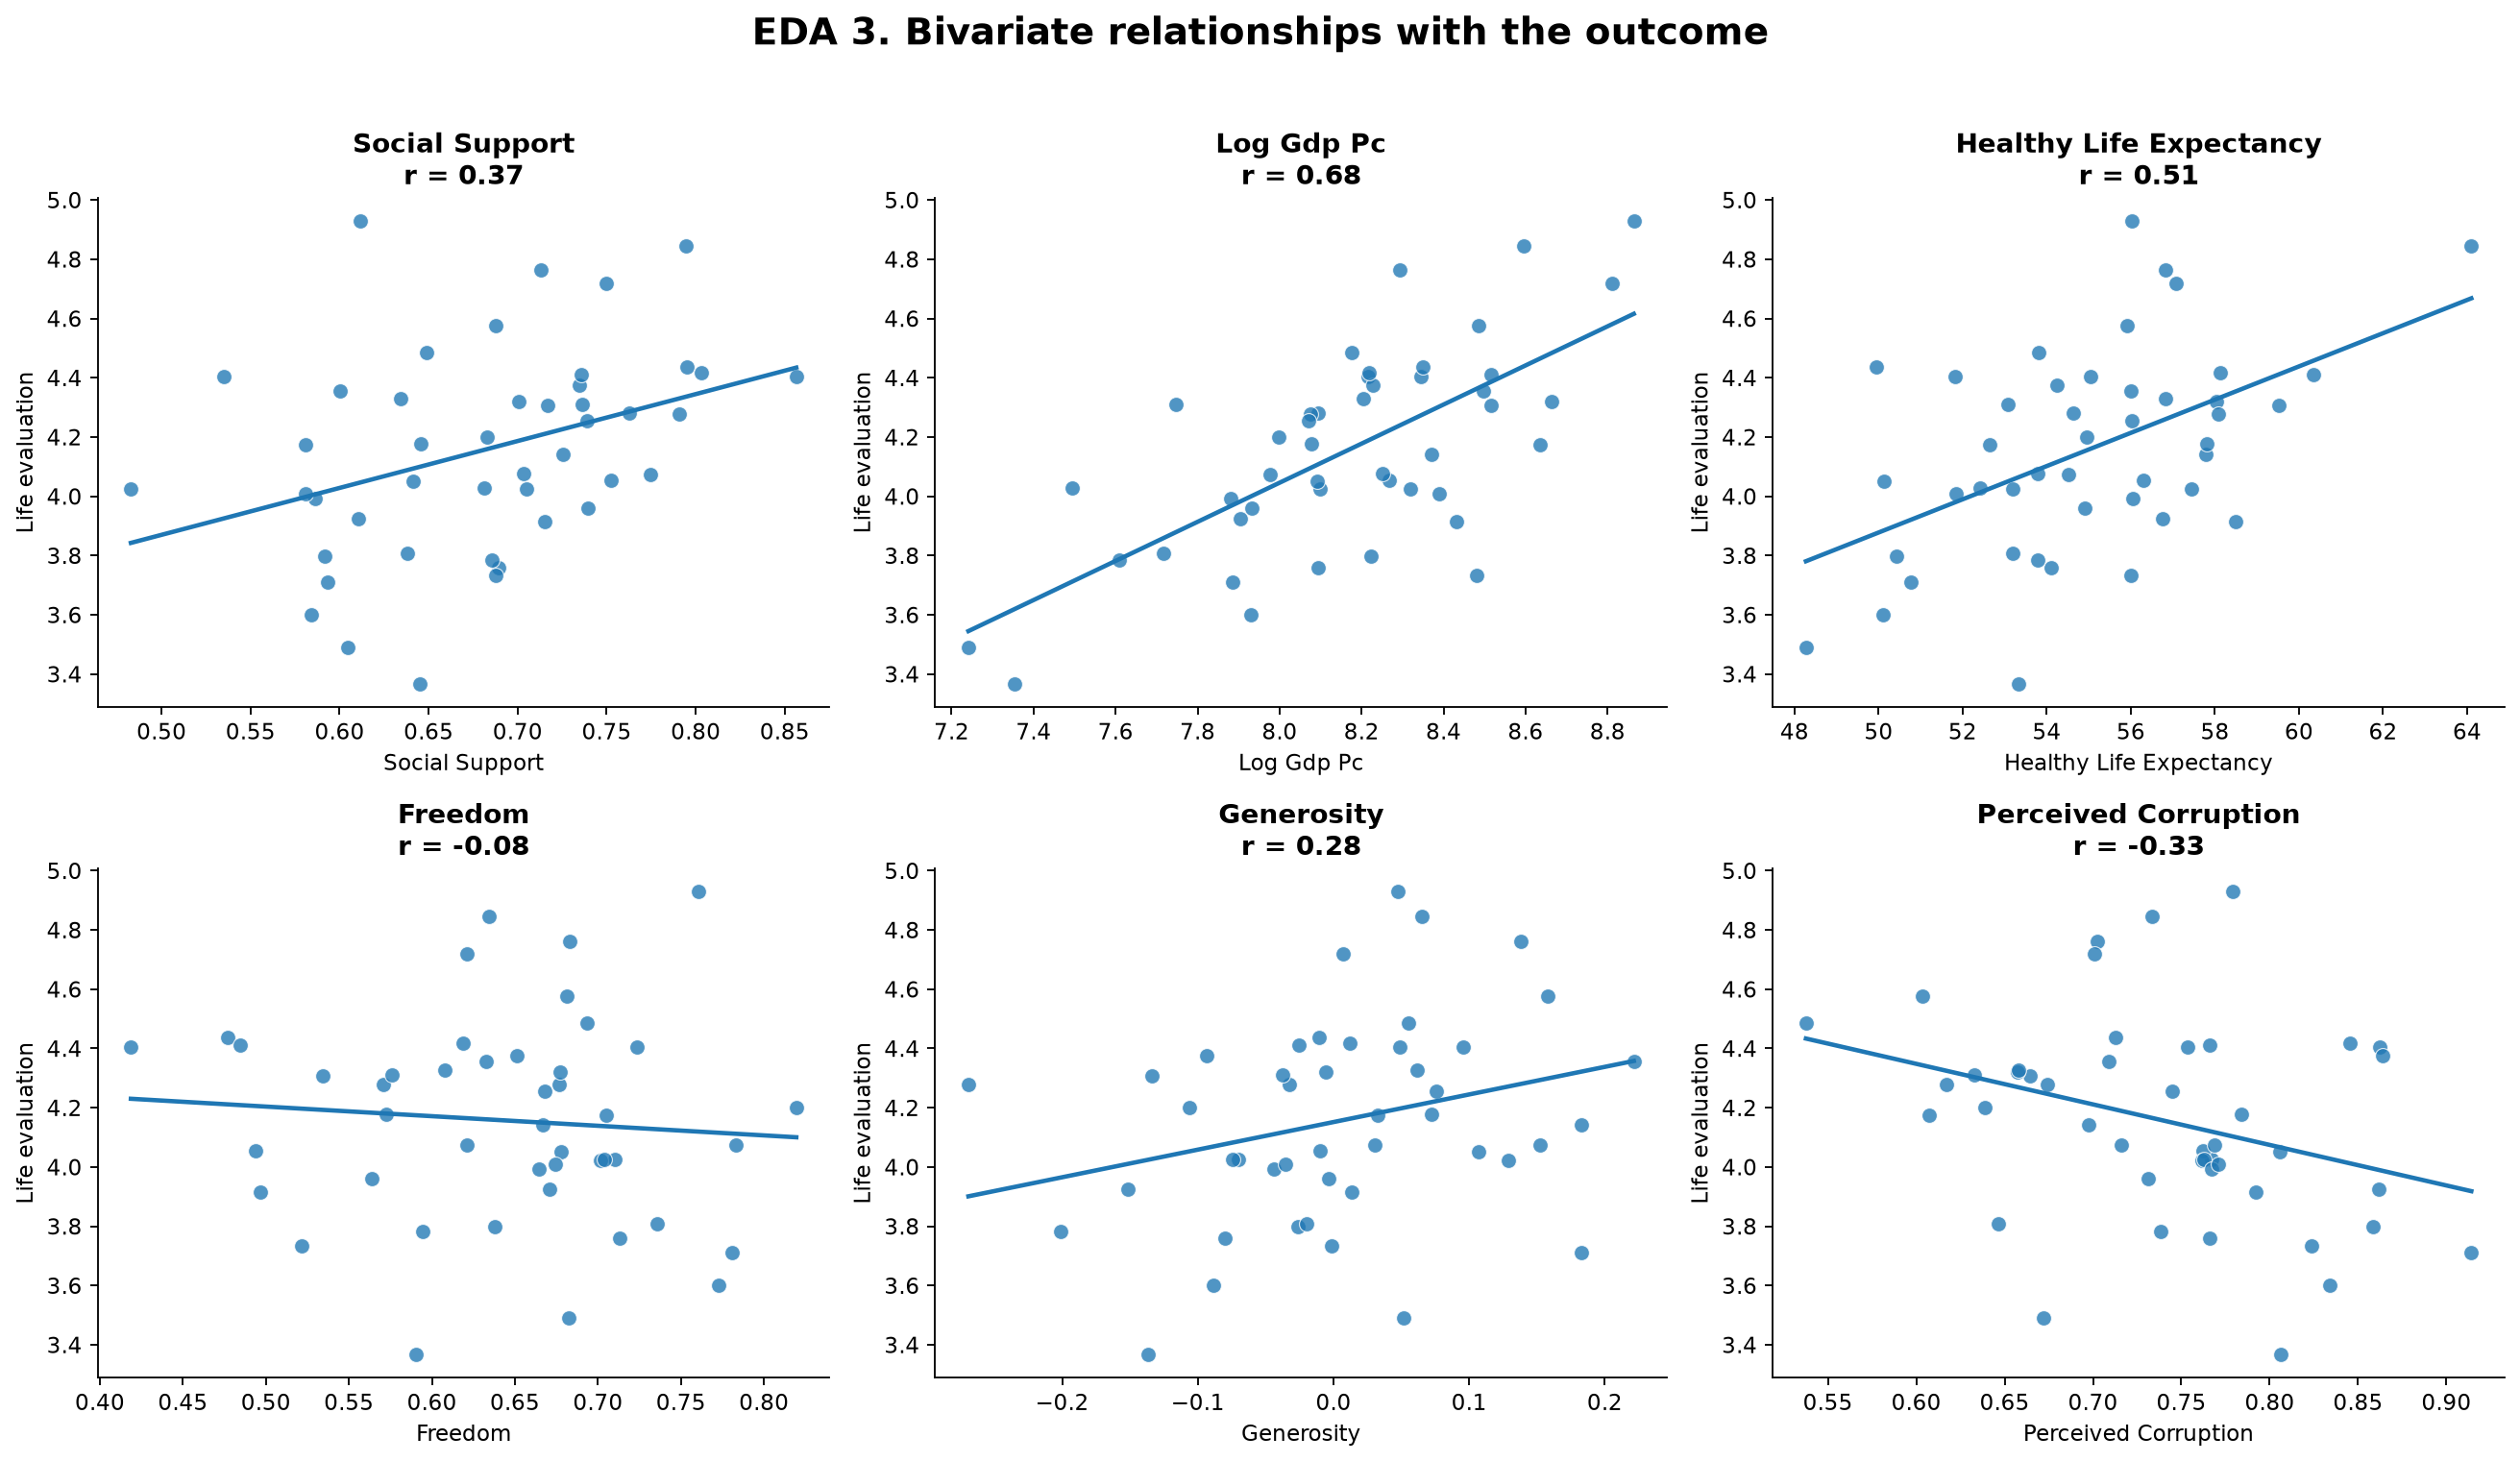

In [7]:
fig, axes = plt.subplots(2,3,figsize=(16,9))
biv_results=[]
for ax,var in zip(axes.ravel(),predictors):
    x=ssa[var].values; yv=ssa["life_evaluation"].values
    ax.scatter(x,yv,s=48,alpha=.78,edgecolor="white",linewidth=.5)
    m,b=np.polyfit(x,yv,1)
    xs=np.linspace(x.min(),x.max(),100)
    ax.plot(xs,m*xs+b,linewidth=2)
    r=np.corrcoef(x,yv)[0,1]
    biv_results.append([var,r])
    ax.set_title(f"{var.replace('_',' ').title()}\nr = {r:.2f}",weight="bold")
    ax.set_xlabel(var.replace("_"," ").title())
    ax.set_ylabel("Life evaluation")
    ax.spines[["top","right"]].set_visible(False)
fig.suptitle("EDA 3. Bivariate relationships with the outcome",fontsize=17,weight="bold",y=1.02)
plt.tight_layout()
plt.show()

biv_table=pd.DataFrame(biv_results,columns=["Predictor","Pearson r with life_evaluation"])
biv_table["Absolute r"]=biv_table["Pearson r with life_evaluation"].abs()
display(biv_table.sort_values("Absolute r",ascending=False).drop(columns="Absolute r").round(3))

### How to read the bivariate panels
- An upward trend suggests a **positive descriptive association**.
- A downward trend suggests a **negative descriptive association**.
- A flatter cloud suggests a weaker linear relationship.
- Pearson's `r` summarizes linear association from −1 to +1.

### Study interpretation
These plots answer: **which variables appear related to the synthetic outcome before geography is considered?**

This matters because GWR later asks whether those relationships are **spatially stable or geographically varying**. A global scatterplot can hide local heterogeneity.

**Do not interpret these correlations as causal effects.**

## 8. Correlation structure and multicollinearity screen
**What we are trying to achieve:** inspect whether predictors are strongly related to one another before fitting GWR.

Strong predictor–predictor correlation can make regression coefficients unstable and difficult to interpret. This is especially important in local models, where effective local information is smaller than the full dataset.

                Predictor 1              Predictor 2      r
2            social_support                  freedom -0.543
5                log_gdp_pc  healthy_life_expectancy  0.482
1            social_support  healthy_life_expectancy  0.465
9   healthy_life_expectancy                  freedom -0.323
7                log_gdp_pc               generosity  0.311
4            social_support     perceived_corruption -0.193
6                log_gdp_pc                  freedom -0.152
11  healthy_life_expectancy     perceived_corruption -0.149
0            social_support               log_gdp_pc  0.145
3            social_support               generosity -0.106


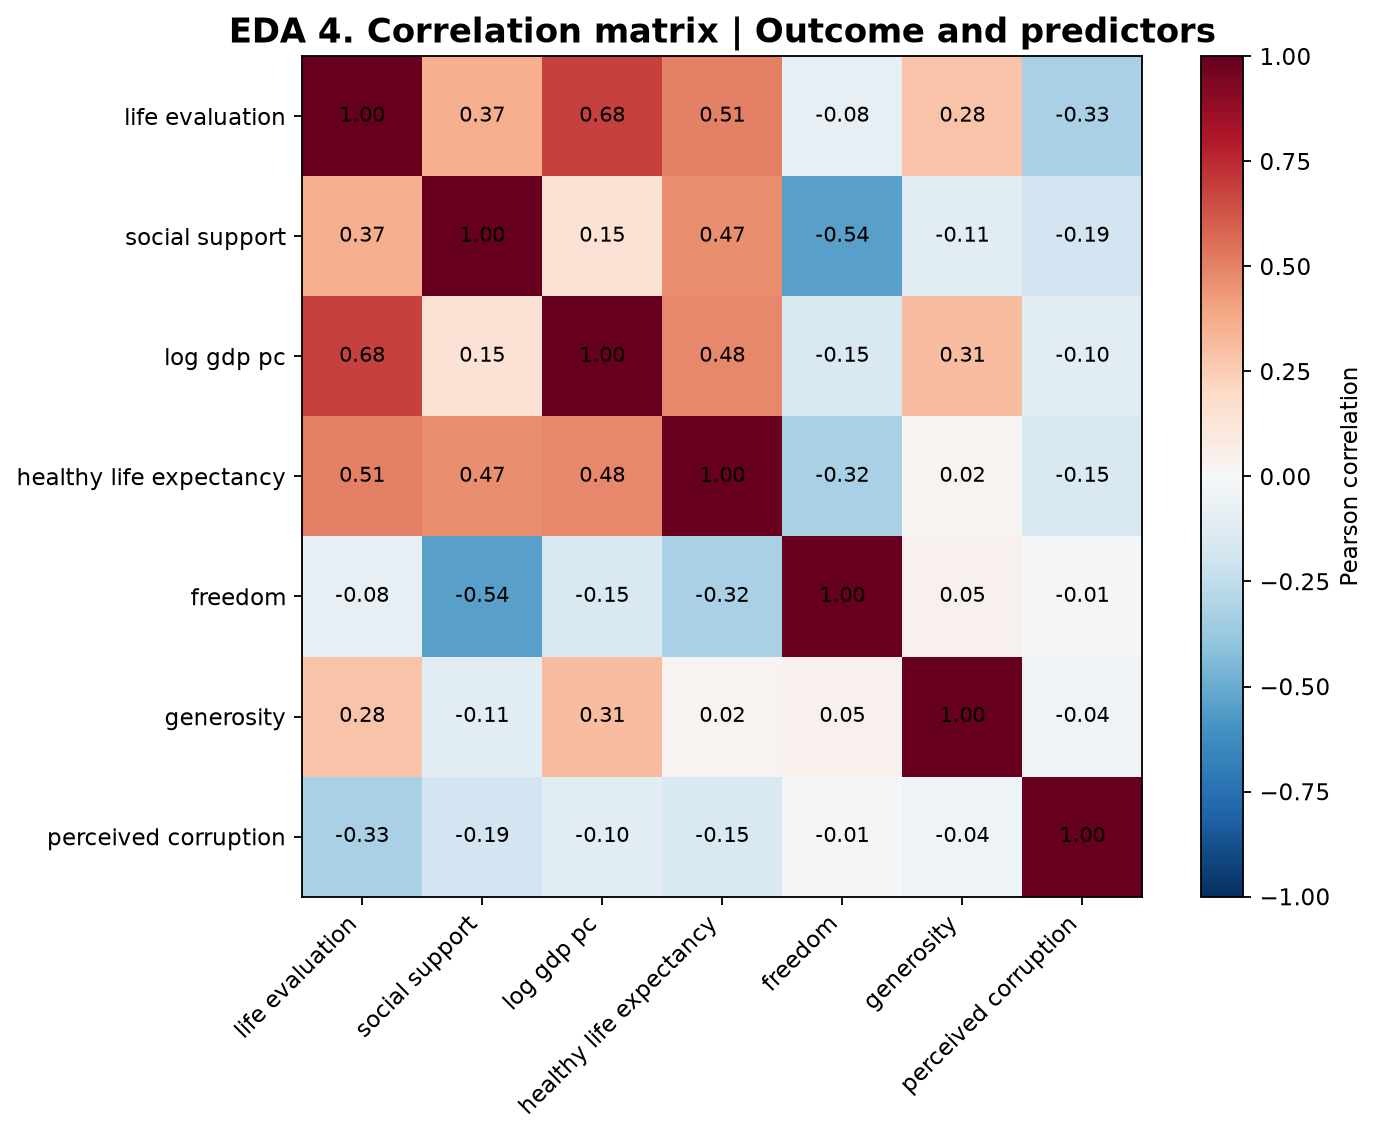

In [8]:
corr = ssa[["life_evaluation"]+predictors].corr()
fig, ax = plt.subplots(figsize=(9,7))
im=ax.imshow(corr.values,vmin=-1,vmax=1,cmap="RdBu_r")
ax.set_xticks(range(len(corr.columns)),[c.replace("_"," ") for c in corr.columns],rotation=45,ha="right")
ax.set_yticks(range(len(corr.index)),[c.replace("_"," ") for c in corr.index])
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center",fontsize=9)
ax.set_title("EDA 4. Correlation matrix | Outcome and predictors",fontsize=15,weight="bold")
fig.colorbar(im,ax=ax,label="Pearson correlation")
plt.tight_layout()
plt.show()

pairs=[]
for i,a in enumerate(predictors):
    for b in predictors[i+1:]:
        pairs.append([a,b,corr.loc[a,b]])
pair_df=pd.DataFrame(pairs,columns=["Predictor 1","Predictor 2","r"])
display(pair_df.reindex(pair_df.r.abs().sort_values(ascending=False).index).head(10).round(3))

### Interpretation
Focus especially on large absolute correlations between **predictors**, not just predictor–outcome correlations.

If two predictors are strongly correlated, their coefficients may compete to explain similar information. In a real GWR analysis, this would motivate formal collinearity diagnostics, sensitivity analyses, variable reduction, or a different model specification.

### EDA checkpoint
At this point we understand:
1. the outcome distribution,
2. each predictor's distribution,
3. global predictor–outcome relationships,
4. predictor–predictor correlation.

We are now ready to ask the spatial question:

> **Where are outcome values high or low, and are those patterns statistically unusual?**

# PART C | MAP IT: descriptive geography

## 9. Create a publication-ready choropleth of the outcome
**Question:** Where are synthetic life-evaluation values high or low?

A choropleth is descriptive. It helps us see geographic variation, but it does **not** test whether neighboring high or low values form statistically unusual clusters.

Five highest synthetic outcome values:
         ADMIN  life_evaluation
38     Eritrea            4.930
36  Madagascar            4.845
17    Cameroon            4.763
39    Ethiopia            4.718
35     Burundi            4.577
Five lowest synthetic outcome values:
            ADMIN  life_evaluation
23        Liberia            3.366
24   Sierra Leone            3.489
37         Gambia            3.601
22  Guinea-Bissau            3.712
43         Rwanda            3.733
✓ Figure exported at 300 dpi: EvidenceLab12_C1_Choropleth.png


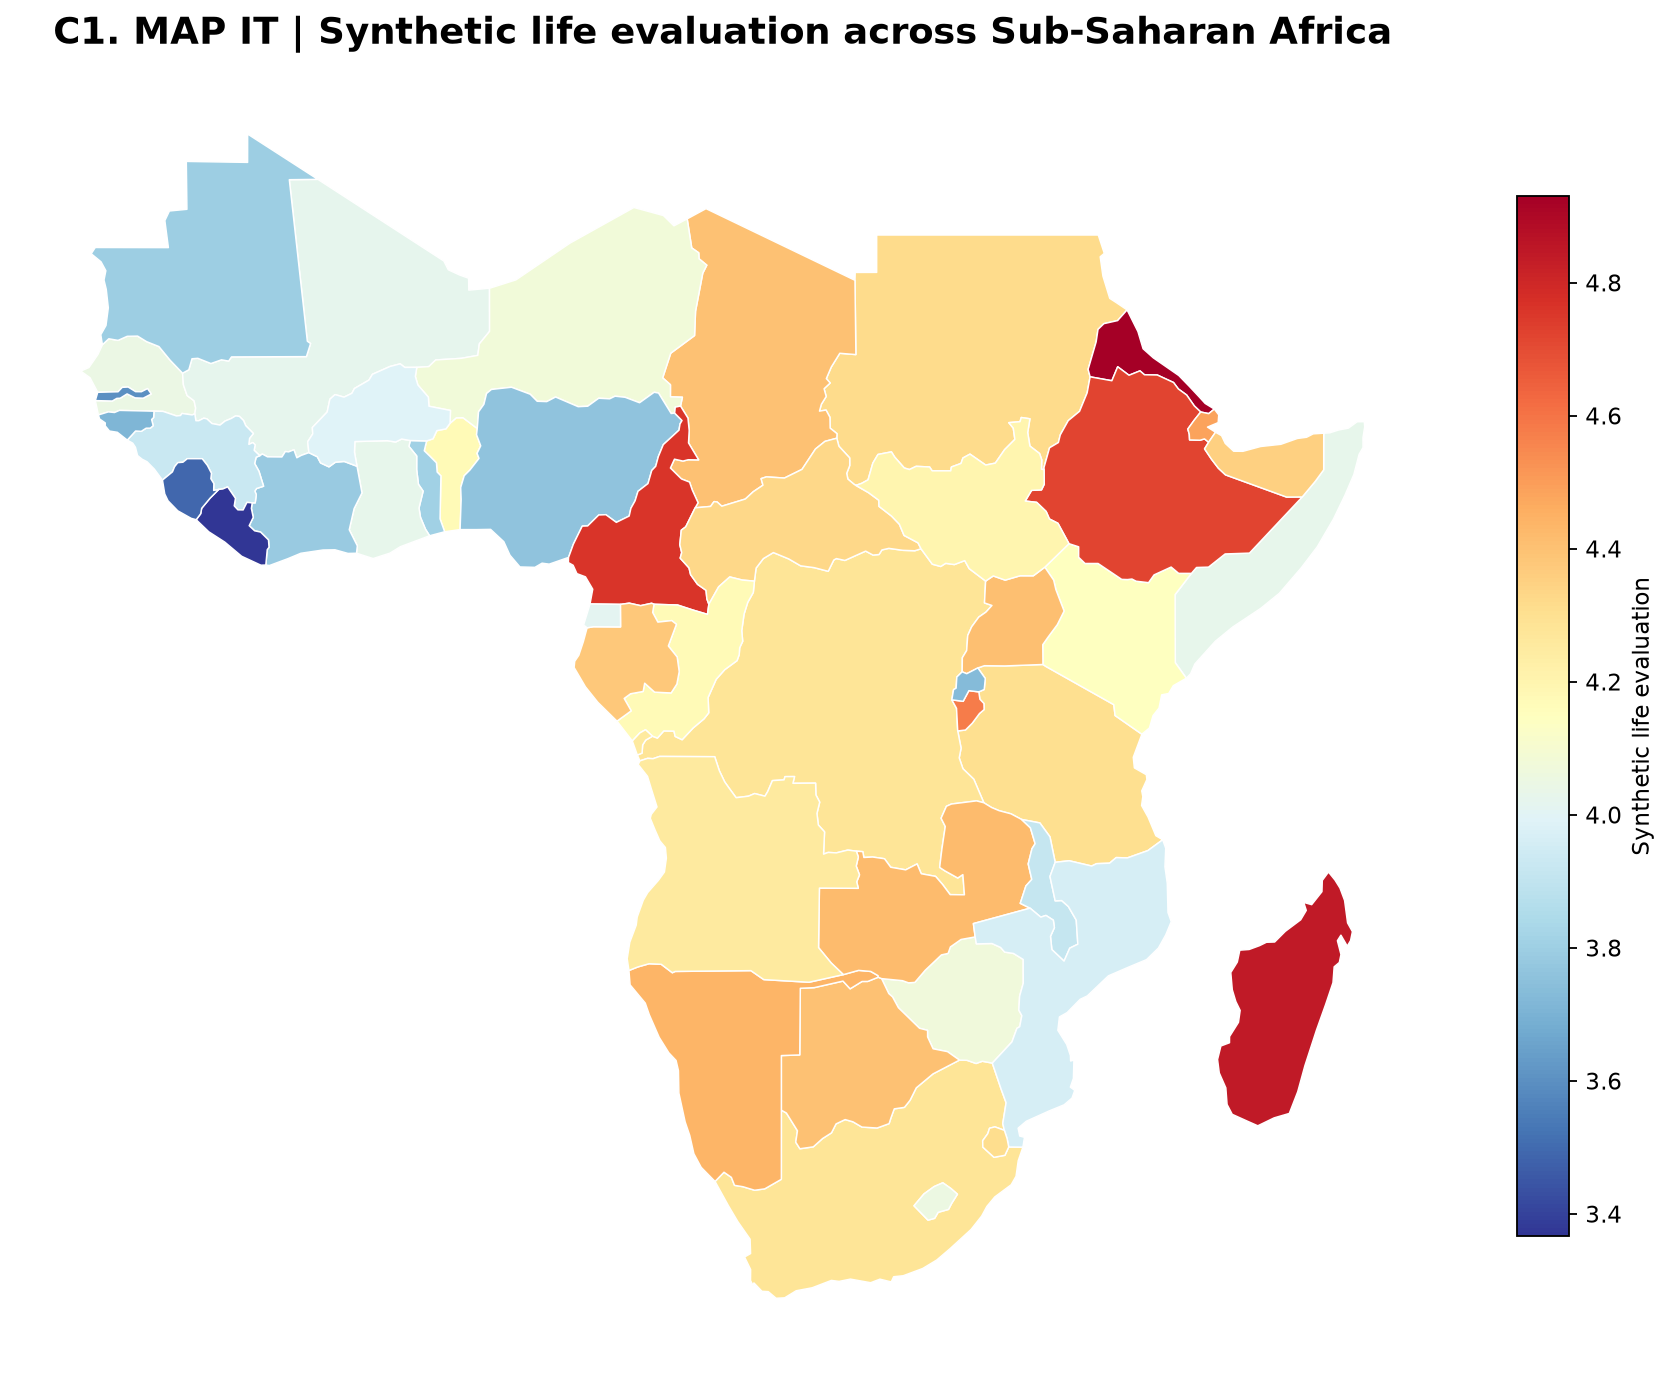

In [9]:
plot_map = ssa.to_crs(4326)
fig, ax = plt.subplots(figsize=(11,10))
plot_map.plot(column="life_evaluation", cmap="RdYlBu_r", legend=True,
              edgecolor="white", linewidth=.65, ax=ax,
              legend_kwds={"label":"Synthetic life evaluation","shrink":.65})
ax.set_title("C1. MAP IT | Synthetic life evaluation across Sub-Saharan Africa",
             fontsize=16, weight="bold", pad=14)
ax.axis("off")
plt.tight_layout()
plt.savefig("EvidenceLab12_C1_Choropleth.png",dpi=300,bbox_inches="tight")
plt.show()

top = ssa.nlargest(5,"life_evaluation")[["ADMIN","life_evaluation"]]
bottom = ssa.nsmallest(5,"life_evaluation")[["ADMIN","life_evaluation"]]
print("Five highest synthetic outcome values:")
display(top.round(3))
print("Five lowest synthetic outcome values:")
display(bottom.round(3))
print("✓ Figure exported at 300 dpi: EvidenceLab12_C1_Choropleth.png")

### How to interpret the choropleth
The map answers **where values appear high or low**. Hovering lets you inspect the synthetic outcome and selected predictors for each area.

It does **not** answer:
- whether neighboring high values form a statistically significant hotspot,
- whether a dense-looking area is unusual relative to its neighbors,
- what explains the pattern.

A visually high area could arise from the outcome-generating process, population structure, measurement intensity, program activity, mobility, reporting, denominators, or other mechanisms in a real study.

**Key takeaway:** **MAP IT ≠ TEST THE CLUSTER.**

# PART D | TEST THE CLUSTER: Getis-Ord Gi*

## 10. Define spatial neighbors
**What we are trying to achieve:** tell the statistic which areas count as spatial neighbors.

We start with Queen contiguity, where polygons sharing a boundary or vertex are neighbors. Because islands can be disconnected, the code falls back to 4-nearest neighbors when needed.

**Why it matters:** hotspot results can change when the spatial-neighbor definition changes. The choice should be scientifically justified in a real study.

In [10]:
w_queen = Queen.from_dataframe(ssa, use_index=True)
print("Queen-contiguity islands:", [ssa.loc[i,"ADMIN"] for i in w_queen.islands])

if w_queen.islands:
    w = KNN.from_dataframe(ssa, k=4)
    weights_used = "4-nearest neighbors (KNN)"
else:
    w = w_queen
    weights_used = "Queen contiguity"
w.transform = "R"

neighbor_counts = pd.Series({i:len(w.neighbors[i]) for i in w.neighbors})
print(f"✓ Spatial weights used: {weights_used}")
print(f"Neighbor count range: {neighbor_counts.min()} to {neighbor_counts.max()}")

Queen-contiguity islands: ['Madagascar']
✓ Spatial weights used: 4-nearest neighbors (KNN)
Neighbor count range: 4 to 4


## 11. Run Getis-Ord Gi*
**Research question:** Which areas belong to statistically significant local clusters of high or low `life_evaluation` values relative to neighboring areas?

We use permutation inference to estimate local significance.

- **Hot spot:** significant local concentration of high values.
- **Cold spot:** significant local concentration of low values.
- **Not significant:** insufficient evidence of unusual local clustering at the selected threshold.

This is a local clustering test, not a causal model.

In [11]:
g = G_Local(ssa["life_evaluation"].values, w, permutations=999, star=True, n_jobs=1, seed=42)
ssa["gi_z"] = g.Zs
ssa["gi_p"] = g.p_sim
ssa["gi_class"] = "Not significant"
ssa.loc[(ssa.gi_p < .05) & (ssa.gi_z > 0), "gi_class"] = "Hot spot"
ssa.loc[(ssa.gi_p < .05) & (ssa.gi_z < 0), "gi_class"] = "Cold spot"

gi_table = ssa[["ADMIN","life_evaluation","gi_z","gi_p","gi_class"]].sort_values("gi_z",ascending=False)
display(gi_table.round(4))

n_hot=(ssa.gi_class=="Hot spot").sum()
n_cold=(ssa.gi_class=="Cold spot").sum()
n_ns=(ssa.gi_class=="Not significant").sum()
print(f"RESULT: {n_hot} hot spot(s), {n_cold} cold spot(s), {n_ns} not significant.")
print("Interpretation: significant areas are clusters relative to their neighbors, not proof of a causal mechanism.")

                               ADMIN  life_evaluation  ...   gi_p         gi_class
38                           Eritrea           4.9304  ...  0.022         Hot spot
4                              Sudan           4.3192  ...  0.008         Hot spot
39                          Ethiopia           4.7180  ...  0.045         Hot spot
40                          Djibouti           4.4863  ...  0.020         Hot spot
41                        Somaliland           4.3546  ...  0.016         Hot spot
44                       South Sudan           4.2008  ...  0.066  Not significant
26          Central African Republic           4.3282  ...  0.080  Not significant
34                            Angola           4.2548  ...  0.076  Not significant
2                            Somalia           4.0262  ...  0.058  Not significant
27             Republic of the Congo           4.1776  ...  0.118  Not significant
28                             Gabon           4.3757  ...  0.181  Not significant
9   

## 12. Map the Gi* findings with a publication-ready classification map
**What we are trying to achieve:** connect the statistical test back to geography.

The complete results table above preserves country-level outcome values, Gi* z-scores, permutation p-values and classifications. The map below prioritizes stable visual interpretation and clean export.

✓ Red = significant high-value cluster | Blue = significant low-value cluster | Grey = not significant
✓ Figure exported at 300 dpi: EvidenceLab12_D1_GetisOrdGi.png


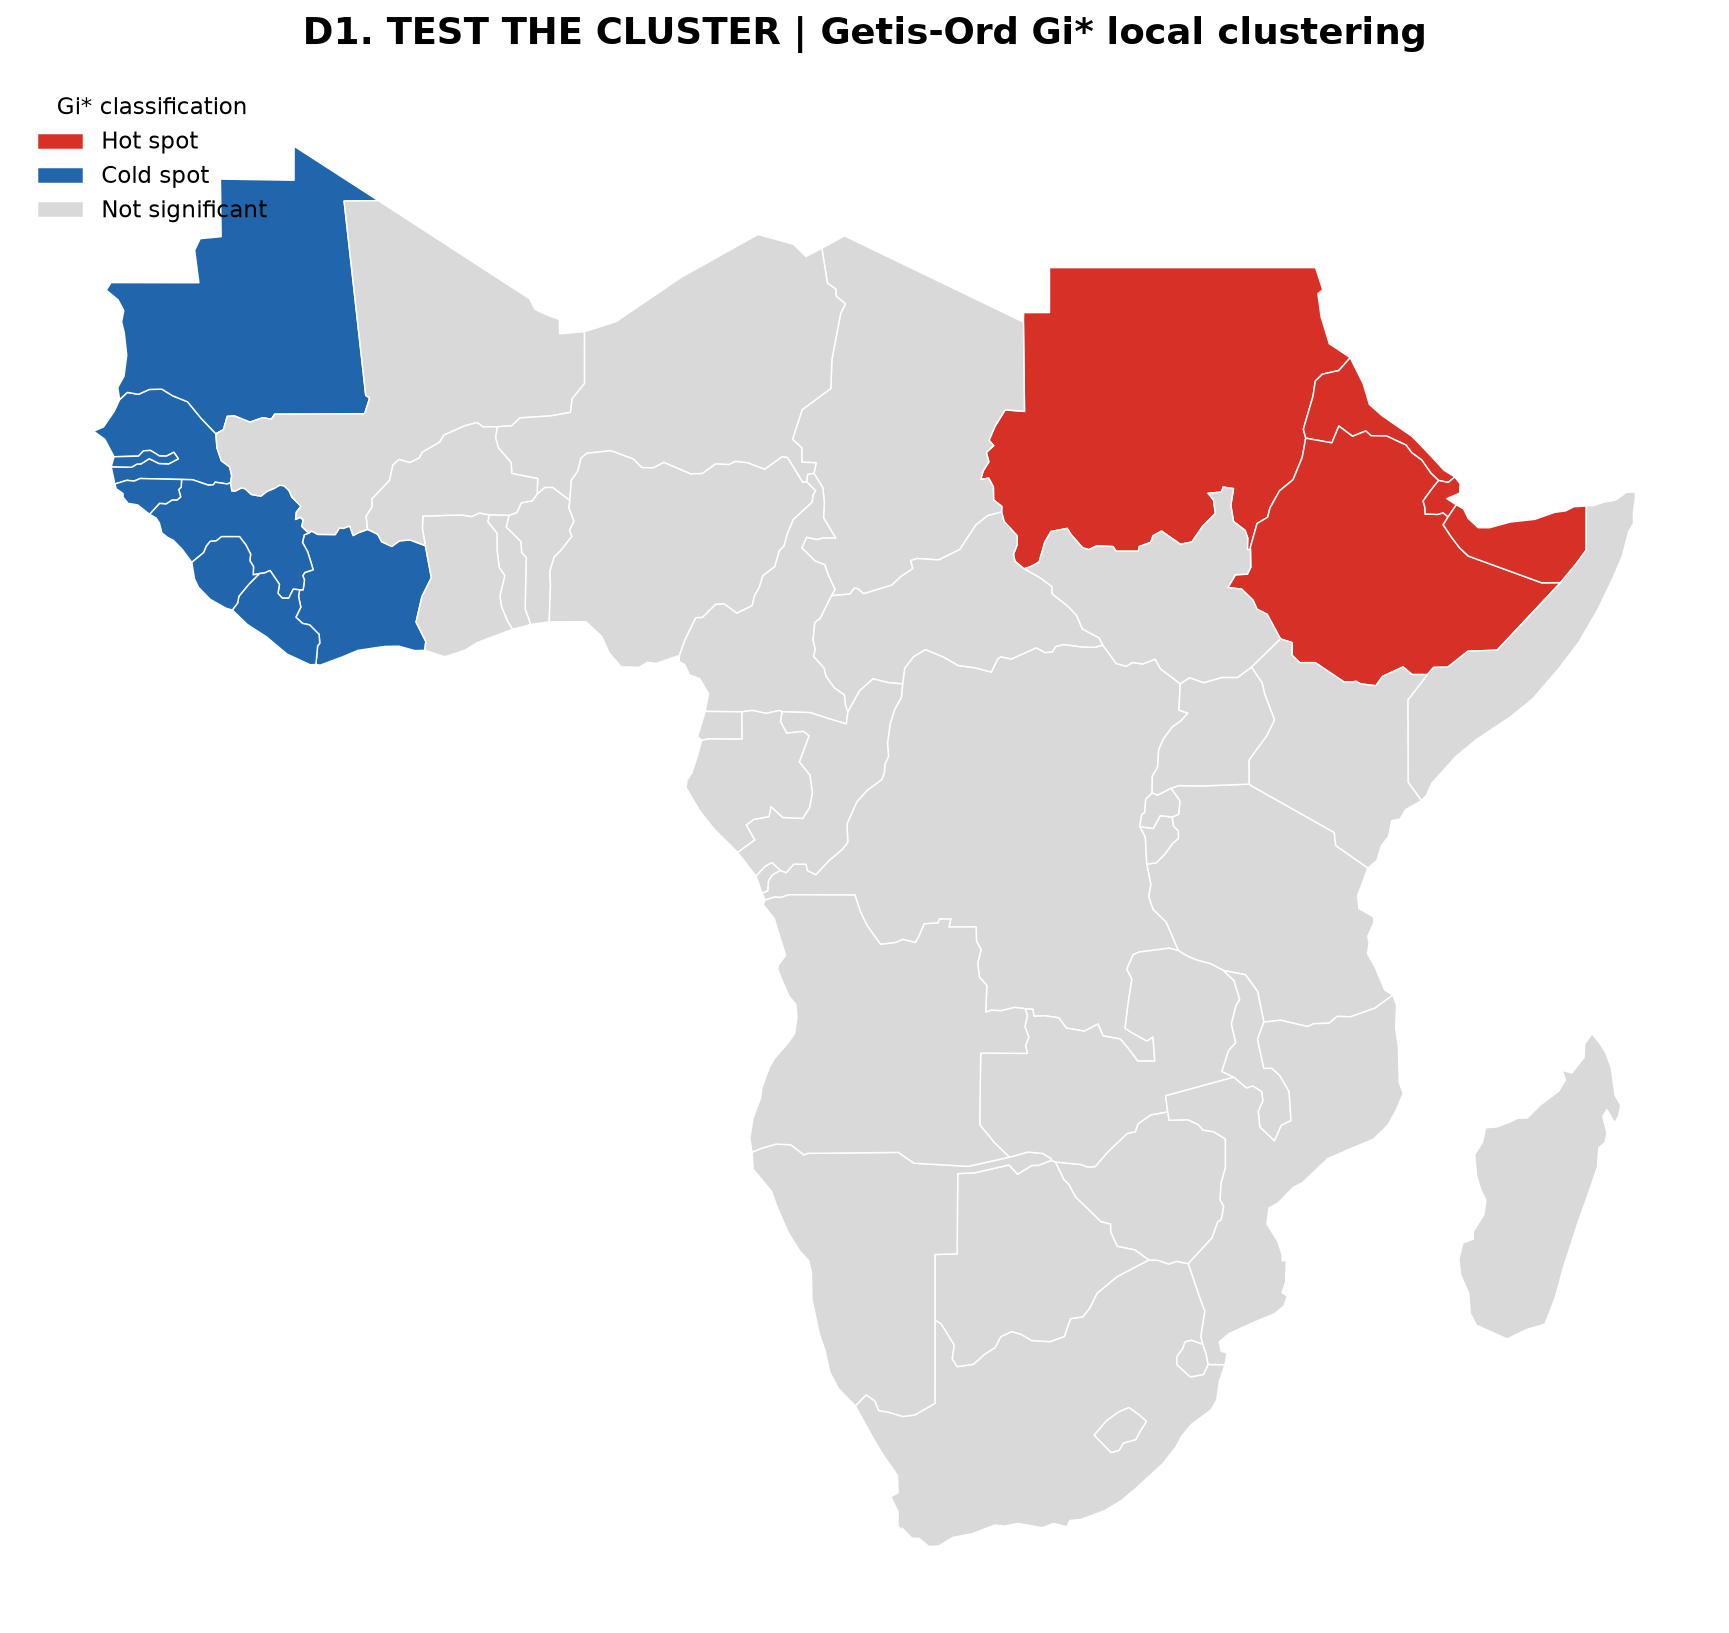

In [12]:
plot_gi = ssa.to_crs(4326).copy()
palette={"Hot spot":"#d73027","Cold spot":"#2166ac","Not significant":"#d9d9d9"}

fig, ax = plt.subplots(figsize=(11,10))
for label in ["Hot spot","Cold spot","Not significant"]:
    part=plot_gi[plot_gi["gi_class"].astype(str)==label]
    part.plot(ax=ax,color=palette[label],edgecolor="white",linewidth=.65,label=label)
ax.set_title("D1. TEST THE CLUSTER | Getis-Ord Gi* local clustering",
             fontsize=16,weight="bold",pad=14)
ax.legend(title="Gi* classification",frameon=False,loc="upper left")
ax.axis("off")
plt.tight_layout()
plt.savefig("EvidenceLab12_D1_GetisOrdGi.png",dpi=300,bbox_inches="tight")
plt.show()

print("✓ Red = significant high-value cluster | Blue = significant low-value cluster | Grey = not significant")
print("✓ Figure exported at 300 dpi: EvidenceLab12_D1_GetisOrdGi.png")

### Robust interpretation of the Gi* result
Read the Gi* map together with the choropleth.

1. A **hot spot** is not merely an area with a high outcome. It is an area embedded in a statistically unusual local concentration of high values under the specified neighbor structure.
2. A **cold spot** is the analogous concentration of low values.
3. A high-valued country can remain **not significant** if its surrounding pattern does not provide sufficient evidence of local clustering.
4. The result is conditional on the spatial weights and significance rule.

### Epidemiologic meaning
If `life_evaluation` were an outbreak burden instead, a Gi* hot spot could identify a geographic cluster deserving investigation. It would still **not tell us why the cluster exists**.

That leads to the next question:

> **Do selected contextual associations with the outcome vary across space?**

# PART E | LOCALIZE ASSOCIATIONS: GWR

## 13. Specify the GWR model
**Outcome:** `life_evaluation`

**Selected predictors for the teaching model**
- `social_support`
- `log_gdp_pc`
- `healthy_life_expectancy`
- `freedom`

We leave `generosity` and `perceived_corruption` available for learner extensions.

**What GWR adds:** instead of estimating one coefficient for every location, GWR estimates local coefficients using geographically weighted information.

**Important:** local coefficients are spatially varying **associations**, not causal effects. Country-level GWR with a modest number of areas is a teaching demonstration. Real applications require adequate local information, sensitivity analyses, diagnostics, and a defensible bandwidth/kernel choice.

In [13]:
features = ["social_support","log_gdp_pc","healthy_life_expectancy","freedom"]
X_raw = ssa[features].copy()
Y_raw = ssa[["life_evaluation"]].copy()

x_scaler = StandardScaler()
y_scaler = StandardScaler()
X = x_scaler.fit_transform(X_raw)
Y = y_scaler.fit_transform(Y_raw)

coords = np.column_stack([ssa.geometry.centroid.x.values,
                          ssa.geometry.centroid.y.values])

print("Outcome:", "life_evaluation")
print("Predictors:", ", ".join(features))
print("Rows available for GWR:", len(ssa))
print("✓ Variables standardized so local coefficient magnitudes are more comparable.")

Outcome: life_evaluation
Predictors: social_support, log_gdp_pc, healthy_life_expectancy, freedom
Rows available for GWR: 45
✓ Variables standardized so local coefficient magnitudes are more comparable.


## 14. Select the spatial bandwidth and fit GWR
**What we are trying to achieve:** determine how many nearby observations contribute to each local regression, then fit the local model.

The bandwidth is selected algorithmically. Smaller bandwidths emphasize very local information; larger bandwidths approach a more global relationship.

In [14]:
selector = Sel_BW(coords, Y, X, spherical=False)
bw = selector.search(bw_min=max(8, len(features)+3))
gwr_results = GWR(coords, Y, X, bw=bw, fixed=False, kernel="bisquare").fit()

print(f"Selected adaptive bandwidth: {bw}")
print(f"GWR R²: {gwr_results.R2:.3f}")
print(f"GWR adjusted R²: {gwr_results.adj_R2:.3f}")
print(f"AICc: {gwr_results.aicc:.2f}")
print("Interpretation: these are in-sample teaching diagnostics, not external validation.")

Selected adaptive bandwidth: 44.0
GWR R²: 0.666
GWR adjusted R²: 0.579
AICc: 105.29
Interpretation: these are in-sample teaching diagnostics, not external validation.


## 15. Inspect local coefficients and local fit
**What we are trying to achieve:** see whether the estimated associations are similar everywhere or change geographically.

Because predictors and outcome were standardized:
- positive β: higher predictor values are locally associated with higher `life_evaluation`,
- negative β: higher predictor values are locally associated with lower `life_evaluation`,
- values near zero: weaker local association in this fitted model.

We also map local R² as a descriptive measure of how well the local model fits around each location.

In [15]:
param_names = ["Intercept"] + features
for j,name in enumerate(param_names):
    ssa[f"beta_{name}"] = gwr_results.params[:,j]
ssa["local_R2"] = gwr_results.localR2

summary_rows=[]
for f in features:
    vals=ssa[f"beta_{f}"]
    summary_rows.append([f,vals.min(),vals.median(),vals.max(),
                         (vals>0).sum(),(vals<0).sum()])
coef_summary=pd.DataFrame(summary_rows,columns=[
    "Predictor","Min local β","Median local β","Max local β",
    "Areas β > 0","Areas β < 0"])
display(coef_summary.round(3))

                 Predictor  Min local β  ...  Areas β > 0  Areas β < 0
0           social_support        0.058  ...           45            0
1               log_gdp_pc        0.499  ...           45            0
2  healthy_life_expectancy       -0.003  ...           41            4
3                  freedom        0.149  ...           45            0

[4 rows x 6 columns]


## 16. Publication-ready local-coefficient and local-fit maps
The four predictor surfaces are shown together on a common coefficient scale so learners can compare direction and magnitude without dropdown or scrolling conflicts. A separate local R² map shows geographic variation in local model fit.

**Interpretation goal:** look for geographic changes in sign and magnitude, not simply the largest coefficient. The underlying tables retain exact values.

✓ Journal-ready spatial figures exported at 300 dpi.
✓ A common coefficient scale is used across predictors to avoid misleading visual comparisons.


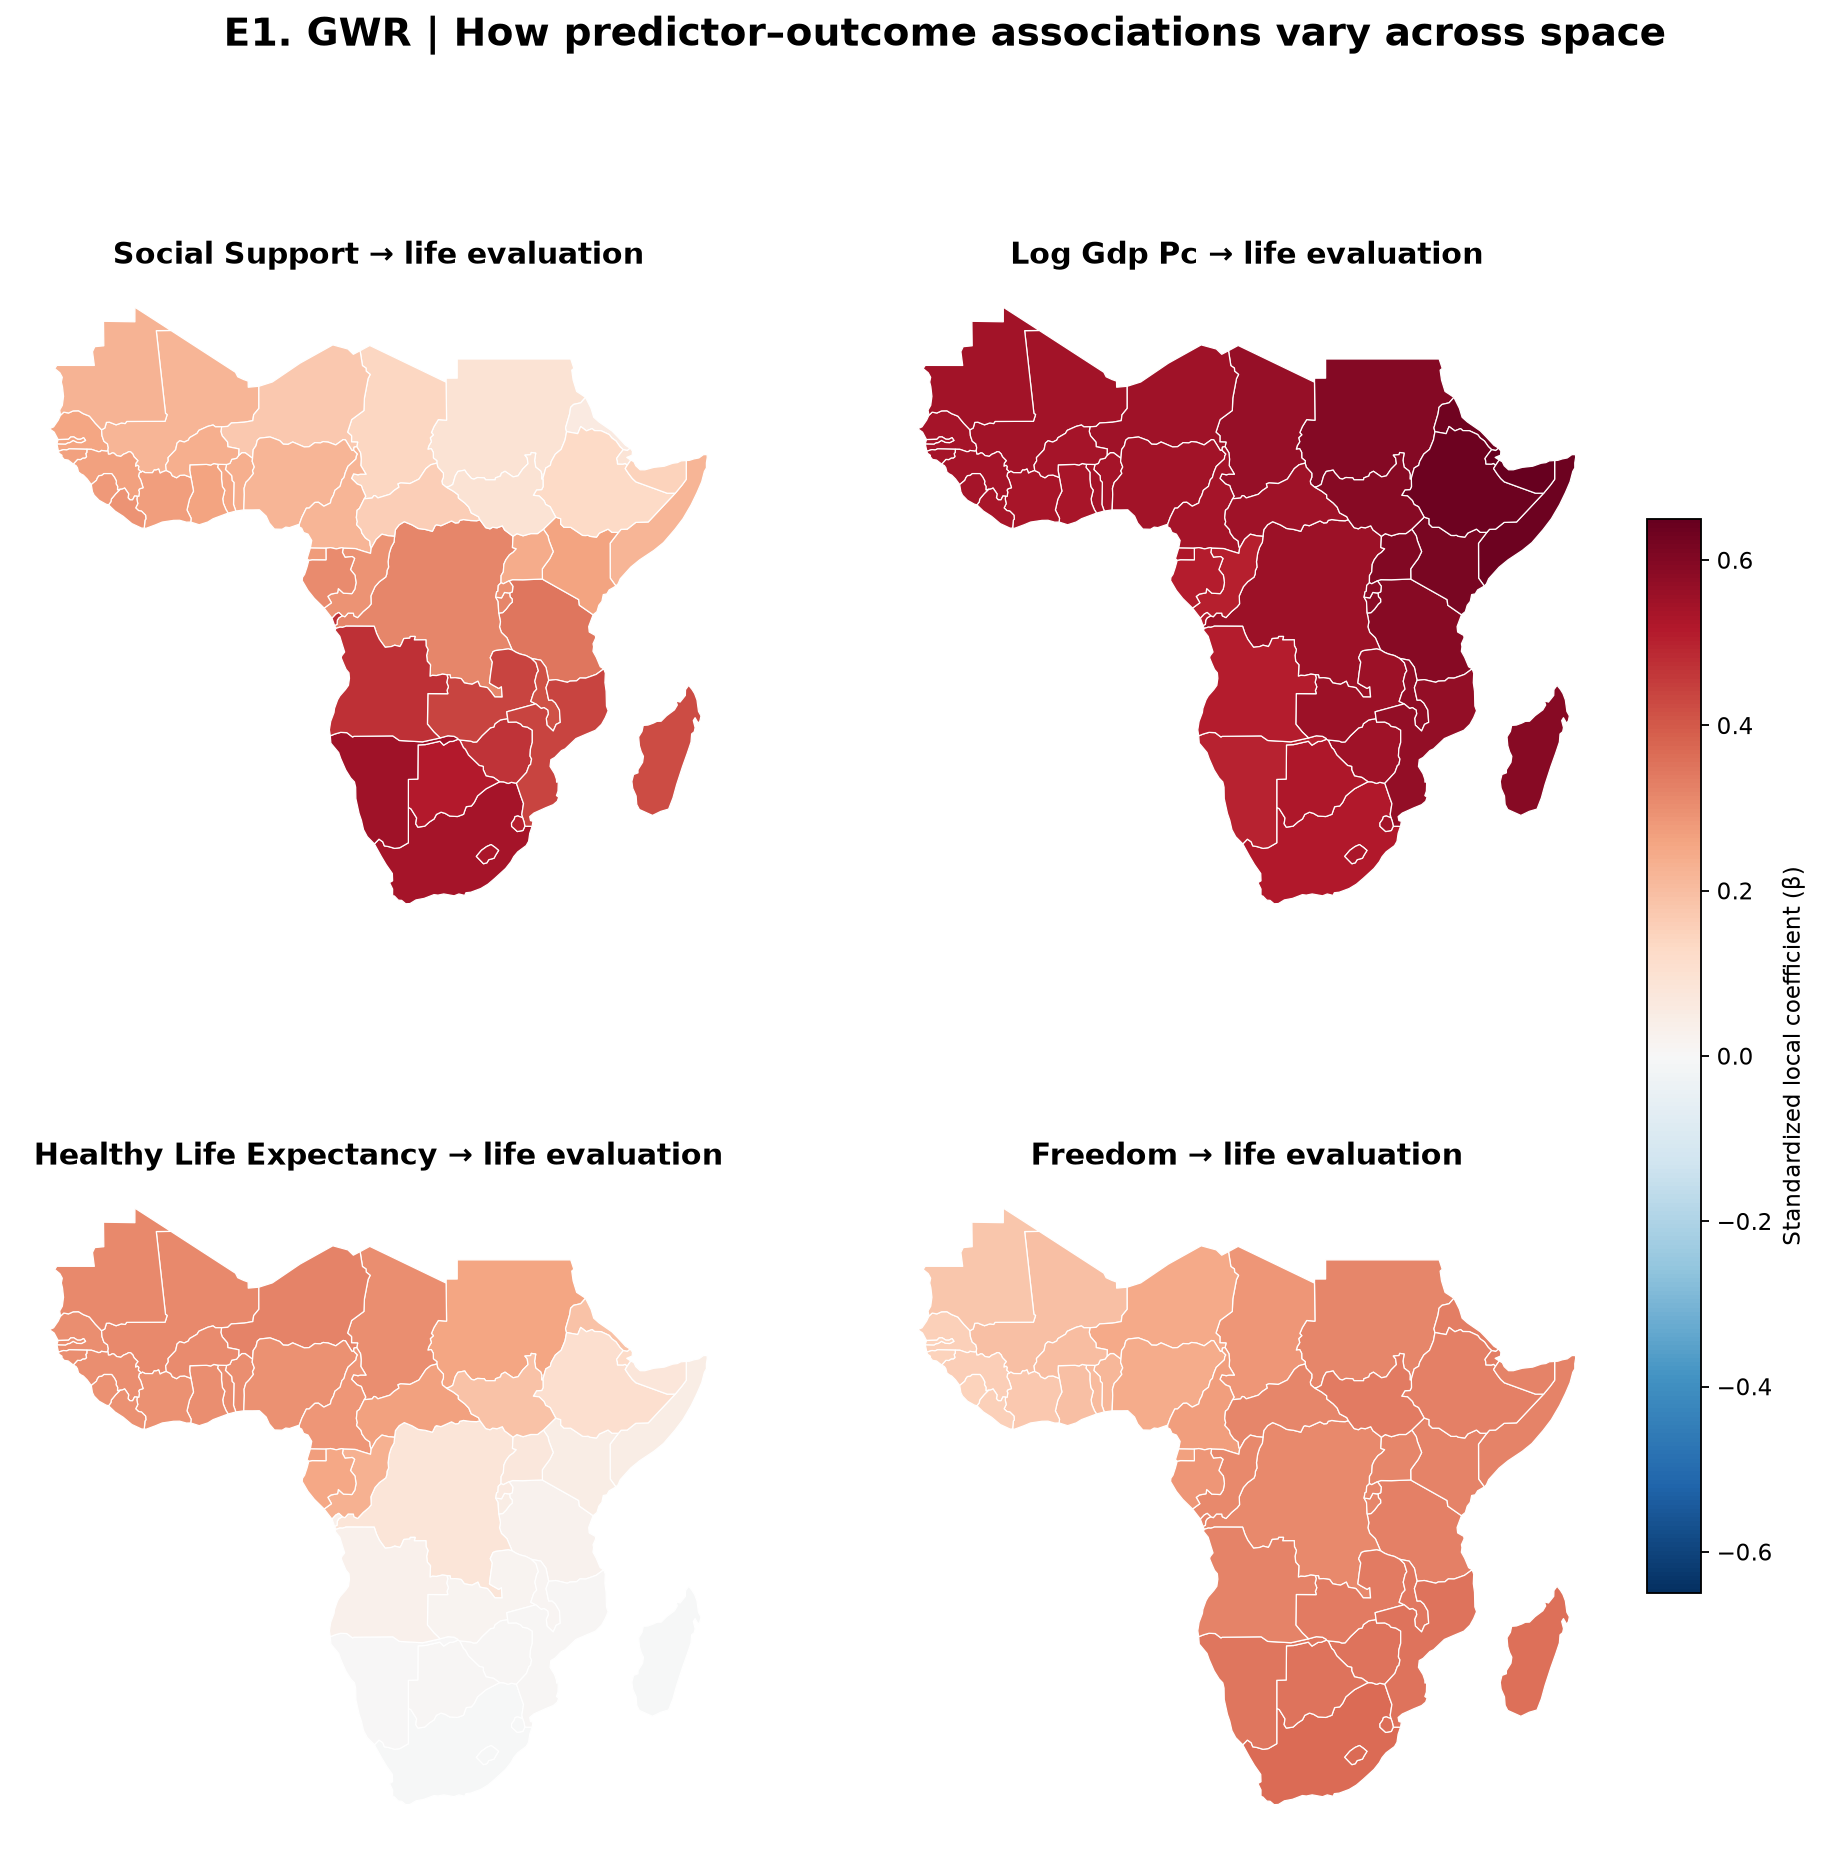

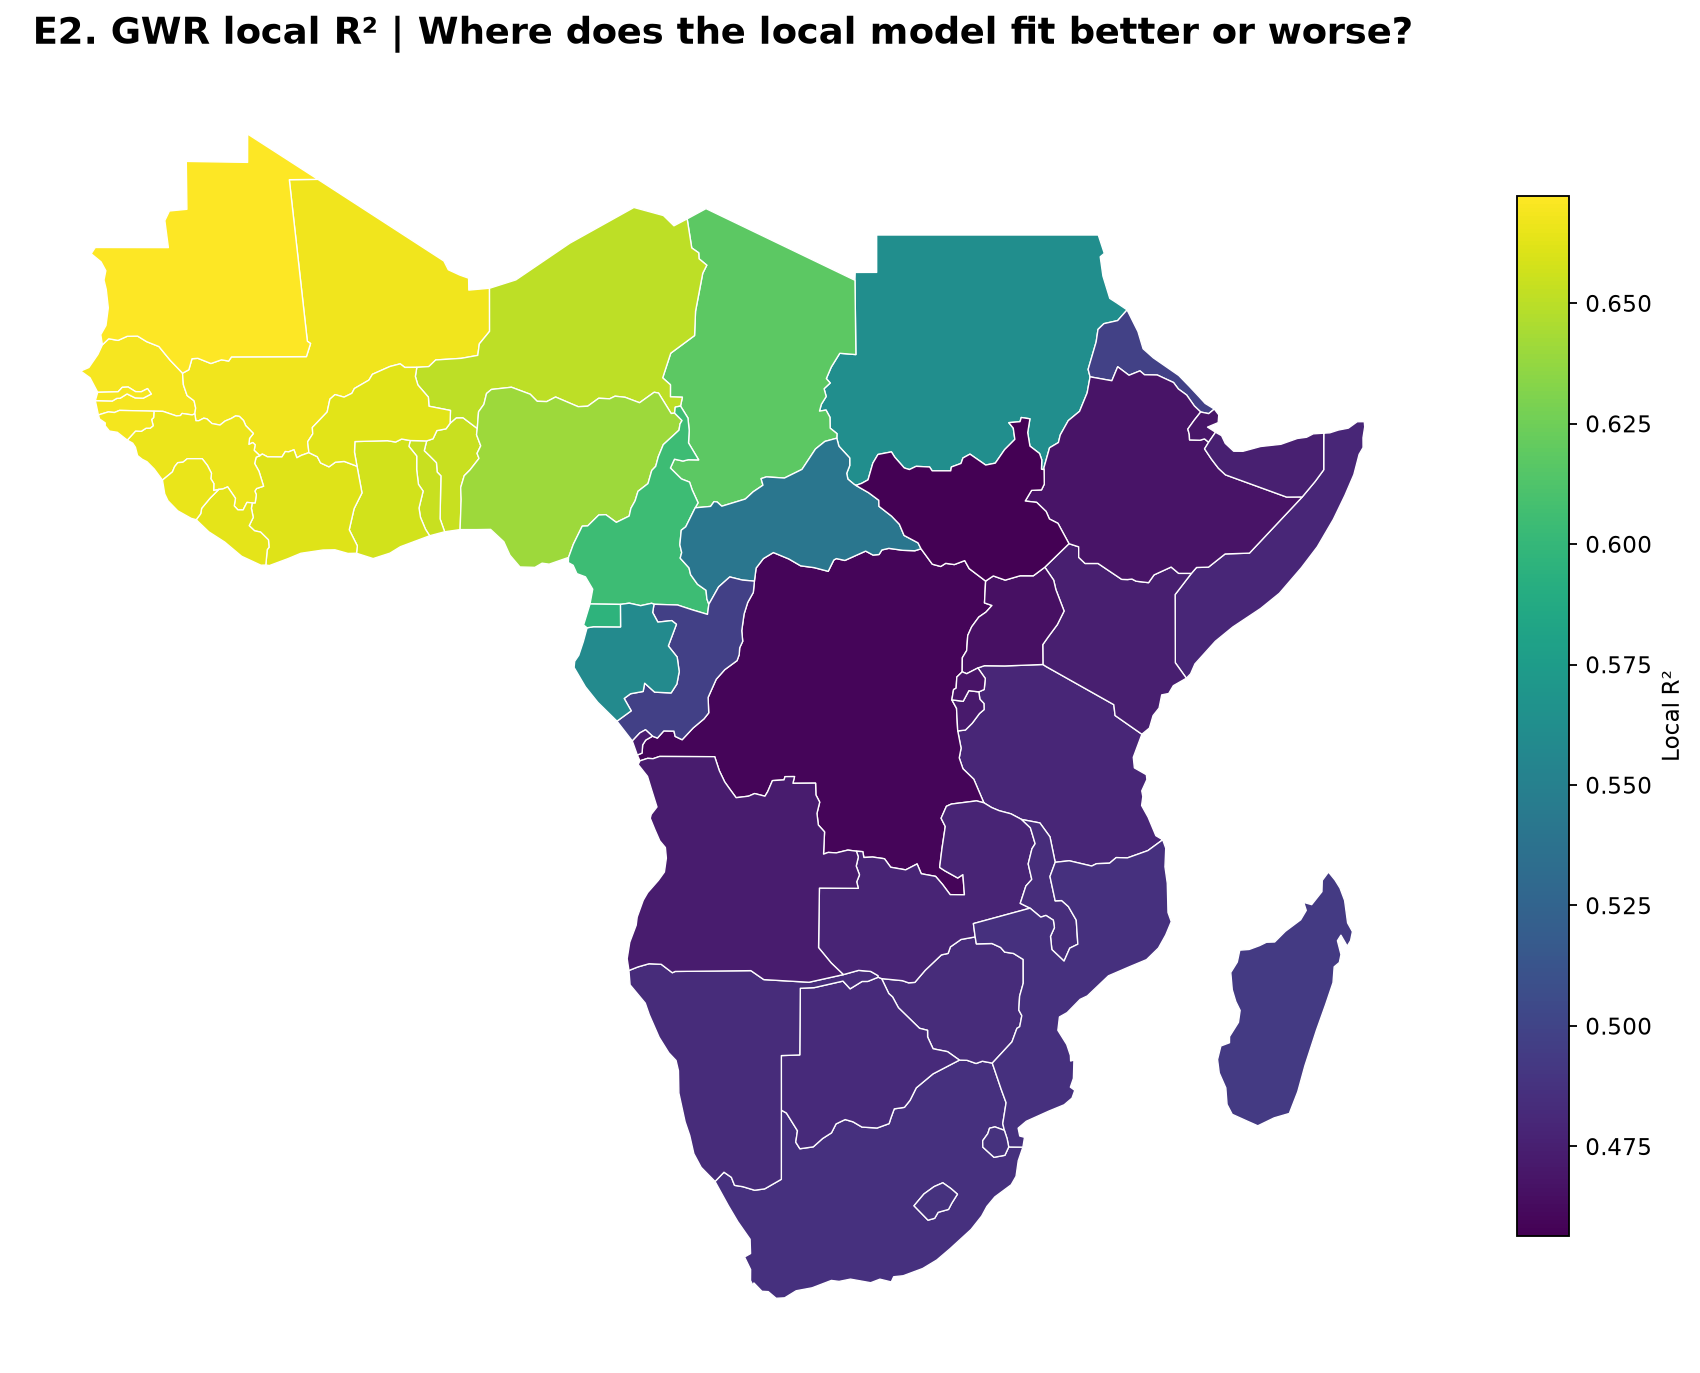

In [16]:
gmap = ssa.to_crs(4326).copy()

# Use one symmetric coefficient scale across all four panels for honest visual comparison.
all_beta=np.concatenate([gmap[f"beta_{f}"].values for f in features])
lim=np.max(np.abs(all_beta))

fig, axes=plt.subplots(2,2,figsize=(15,13))
for ax,f in zip(axes.ravel(),features):
    gmap.plot(column=f"beta_{f}",cmap="RdBu_r",vmin=-lim,vmax=lim,
              edgecolor="white",linewidth=.55,ax=ax)
    ax.set_title(f"{f.replace('_',' ').title()} → life evaluation",weight="bold",fontsize=13)
    ax.axis("off")

sm=plt.cm.ScalarMappable(cmap="RdBu_r",norm=plt.Normalize(-lim,lim))
sm.set_array([])
cbar=fig.colorbar(sm,ax=axes.ravel().tolist(),shrink=.65,pad=.02)
cbar.set_label("Standardized local coefficient (β)")
fig.suptitle("E1. GWR | How predictor–outcome associations vary across space",
             fontsize=17,weight="bold",y=.98)
plt.savefig("EvidenceLab12_E1_GWR_Local_Coefficients.png",dpi=300,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(11,10))
gmap.plot(column="local_R2",cmap="viridis",legend=True,edgecolor="white",
          linewidth=.6,ax=ax,legend_kwds={"label":"Local R²","shrink":.65})
ax.set_title("E2. GWR local R² | Where does the local model fit better or worse?",
             fontsize=16,weight="bold",pad=14)
ax.axis("off")
plt.tight_layout()
plt.savefig("EvidenceLab12_E2_GWR_Local_R2.png",dpi=300,bbox_inches="tight")
plt.show()

print("✓ Journal-ready spatial figures exported at 300 dpi.")
print("✓ A common coefficient scale is used across predictors to avoid misleading visual comparisons.")

### Robust interpretation of the GWR output
The local coefficient maps answer a fundamentally different question from Gi*.

- **Gi*** evaluates whether the **outcome itself** forms unusual local clusters.
- **GWR** evaluates whether selected **predictor–outcome associations** vary across geography.

For each predictor, examine:
1. **Direction:** Is β positive or negative?
2. **Magnitude:** Where is the association stronger or weaker?
3. **Spatial consistency:** Does the sign remain similar across most areas or change?
4. **Local fit:** Where is local R² relatively higher or lower?

### Key takeaway
A GWR surface can suggest that the same predictor is associated differently with the outcome in different places. This can generate stronger implementation or epidemiologic questions, such as:

> Why is social support more strongly associated with life evaluation in one geographic zone than another?

That is a question for further study. **The GWR map itself does not prove the mechanism.**

# PART F | Put the evidence together

## 17. HOTSPOT ≠ DRIVER: integrated interpretation
The two spatial methods should not be treated as competitors. They answer different questions.

| Stage | Method | Question answered | What it does NOT prove |
|---|---|---|---|
| 1 | Choropleth | Where are values high or low? | Statistical hotspot |
| 2 | Getis-Ord Gi* | Where is high/low clustering statistically unusual? | Cause of clustering |
| 3 | GWR | How do selected associations vary by place? | Causal effect |

### The EvidenceLab pathway
**DESCRIBE → TEST CLUSTERING → MODEL LOCAL ASSOCIATIONS → FORM STRONGER QUESTIONS**

In an outbreak study, this workflow could move the analyst from:
1. mapping disease burden,
2. testing whether apparent concentrations are statistically unusual,
3. examining whether candidate contextual associations vary geographically,
4. designing stronger follow-up epidemiologic or implementation studies.

The final step remains essential: **spatial association should inform investigation, not replace causal inference.**

In [17]:
hot_names = ssa.loc[ssa.gi_class=="Hot spot","ADMIN"].tolist()
cold_names = ssa.loc[ssa.gi_class=="Cold spot","ADMIN"].tolist()
strongest={}
for f in features:
    strongest[f]=ssa.loc[ssa[f"beta_{f}"].abs().nlargest(3).index,
                         ["ADMIN",f"beta_{f}"]].round(3).values.tolist()

display(Markdown(f'''
### Automated study summary

**Synthetic outcome:** life evaluation  
**Spatial weights:** {weights_used}  
**Gi* findings:** {n_hot} hot spot(s), {n_cold} cold spot(s), {n_ns} not significant.  
**Hot-spot areas:** {", ".join(hot_names) if hot_names else "None at p < 0.05"}  
**Cold-spot areas:** {", ".join(cold_names) if cold_names else "None at p < 0.05"}  
**GWR adjusted R²:** {gwr_results.adj_R2:.3f}  
**Selected bandwidth:** {bw}

**Interpretation:** The Gi* result identifies where the synthetic outcome forms statistically unusual local clusters under the chosen neighbor definition. The GWR result then shows whether selected contextual associations with the same outcome vary spatially. Neither result establishes causality.
'''))

print("Three largest absolute local coefficients by predictor:")
for f,rows in strongest.items():
    print("\n",f)
    for country,beta in rows:
        print(f"  {country}: β={beta}")

<IPython.core.display.Markdown object>
Three largest absolute local coefficients by predictor:

 social_support
  Namibia: β=0.548
  South Africa: β=0.539
  Lesotho: β=0.529

 log_gdp_pc
  Somaliland: β=0.649
  Djibouti: β=0.646
  Somalia: β=0.639

 healthy_life_expectancy
  Niger: β=0.322
  Mauritania: β=0.311
  Mali: β=0.31

 freedom
  Lesotho: β=0.368
  South Africa: β=0.366
  eSwatini: β=0.364


# PART G | Sensitivity and responsible interpretation

## 18. Sensitivity check: does the hotspot story depend on neighbors?
**Why this matters:** spatial conclusions can depend on how "neighbor" is defined.

This cell compares the primary 4-nearest-neighbor specification with an alternative 6-nearest-neighbor specification. A robust real study should prespecify or justify these choices and report sensitivity.

In [18]:
w6=KNN.from_dataframe(ssa,k=6); w6.transform="R"
g6=G_Local(ssa["life_evaluation"].values,w6,permutations=999, star=True, n_jobs=1,seed=42)
alt=np.where((g6.p_sim<.05)&(g6.Zs>0),"Hot spot",
     np.where((g6.p_sim<.05)&(g6.Zs<0),"Cold spot","Not significant"))
sens=pd.DataFrame({"ADMIN":ssa.ADMIN,
                   "Primary":ssa.gi_class.astype(str),
                   "Alternative_KNN6":alt})
sens["Same classification"]=sens.Primary==sens.Alternative_KNN6
display(sens)
print(f"Classification agreement: {sens['Same classification'].mean()*100:.1f}%")
print("Interpretation: disagreement signals sensitivity to the spatial-neighbor definition and should be investigated, not hidden.")

                               ADMIN  ... Same classification
0        United Republic of Tanzania  ...                True
1   Democratic Republic of the Congo  ...                True
2                            Somalia  ...               False
3                              Kenya  ...                True
4                              Sudan  ...                True
5                               Chad  ...                True
6                       South Africa  ...                True
7                            Lesotho  ...                True
8                           Zimbabwe  ...                True
9                           Botswana  ...                True
10                           Namibia  ...                True
11                           Senegal  ...                True
12                              Mali  ...                True
13                        Mauritania  ...                True
14                             Benin  ...               False
15      

## 19. Final learning review

### What you can now explain
1. Why a thematic/choropleth map is not automatically a hotspot map.
2. Why Getis-Ord Gi* requires an explicit spatial-neighbor definition.
3. How to interpret hot spots, cold spots and non-significant areas.
4. Why a hotspot does not identify its cause.
5. How GWR differs from hotspot detection.
6. How to interpret local β values and local R².
7. Why spatially varying association is not causal effect.
8. Why sensitivity analysis matters.

### Apply it to your own data
Replace the synthetic outcome and predictors with:
- an epidemiologically meaningful rate or outcome,
- justified contextual predictors,
- a defensible geographic unit,
- a scientifically justified spatial-weights definition.

Then ask:
**Where is the outcome unusually clustered? How do selected associations vary by place? What study should test the resulting hypotheses?**

🔔 Follow **Dr. Amobi Andrew Onovo** on LinkedIn and subscribe to the EvidenceLab YouTube series for more applied epidemiology, spatial analysis, statistics, data science and AI.

**EvidenceLab | See it. Understand it. Run it.**

## 20. Self-check quiz
**Q1.** A choropleth shows three adjacent countries with high outcome values. Can you call them a statistically significant hotspot?  
**A1.** No. The map is descriptive. A local spatial statistic such as Getis-Ord Gi* is needed to test clustering under an explicit neighbor definition.

**Q2.** Gi* identifies a hot spot. Does that tell you which predictor caused it?  
**A2.** No. It identifies statistically unusual local clustering of the outcome.

**Q3.** A GWR coefficient is positive in one region and negative in another. What does that mean?  
**A3.** The fitted predictor–outcome association varies in direction across geography. It does not establish a causal effect.

**Q4.** Why compare alternative spatial weights?  
**A4.** Because local-clustering conclusions can depend on how spatial relationships are defined.

**Q5.** What is the integrated workflow?  
**A5.** **MAP IT → TEST THE CLUSTER → LOCALIZE ASSOCIATIONS → FORM STRONGER QUESTIONS.**